# Mini-Project 2: Uganda Tax Engine

An extensible, testable calculator for the main taxes administered by the Uganda Revenue Authority (URA): **PAYE, NSSF, Local Service Tax, VAT and corporate income tax**. As extensions, it also covers **withholding tax, rental income tax** and a **TaxPlanner** that compares salary with dividend.

All code lives in `src/tax/`. This notebook uses it and explains the design. The tests are in `tests/test_tax.py` and `tests/test_money.py`; they include band-edge boundary tests and `hypothesis` property tests.

## 1. Which rates, and which version

The brief's "sample regulatory baseline" for PAYE (nil up to 335,000; then 20%, 25%, 30%) is **not** the schedule URA applied up to June 2026. Checking it against URA uncovered a timeline, and the engine models it:

| Period | Resident monthly PAYE schedule | Source |
|---|---|---|
| 1 Jul 2012 – 30 Jun 2026 | Nil to 235,000 · 10% to 335,000 · 20% to 410,000 · 30% above · +10% above 10,000,000 | Income Tax Act Cap 340, 3rd Schedule, as amended 2012; URA "PAYE rates" page [1] |
| from 1 Jul 2026 | Nil to 335,000 · 20% to 410,000 · 25% to 485,000 · 30% above · +10% above 10,000,000 (**the brief's baseline**) | Income Tax (Amendment) Act 2026, effective 1 Jul 2026 [2] |
| Non-resident (both periods) | 10% to 335,000 · 20% to 410,000 · 30% above · +10% above 10,000,000 | [1]. The 2026/27 non-resident table was not in the sources found, so it is **assumed unchanged** |

Other rates: NSSF 5% employee, 10% employer (NSSF Act, s.11) [3]; VAT 18% standard rate (VAT Act Cap 349) [4]; corporate income tax 30% for resident companies [4]; LST bands from the Local Governments (Amendment) Act 2008 [5]; WHT and rental rates from [4], [6].

Because rates change with each Finance Act, they are **data**: `ScheduleRegistry` picks the schedule in force on the date of the payroll month, and raises `NoScheduleForDateError` outside any known period.

*[1] URA, "PAYE", ura.go.ug, accessed 14 Oct 2026. [2] AfroTools, "Uganda PAYE tax 2026/27", afrotools.com/fr/blog/uganda-paye-tax-2026-27, accessed 14 Oct 2026 (Bill passed 23 Apr 2026, assented 20 Aug 2026). [3] NSSF Act Cap 230. [4] PwC, "Uganda: Corporate and Individual tax summaries", taxsummaries.pwc.com, reviewed Jan 2026. [5] KCCA, "Local Service Tax FAQs", kcca.go.ug. [6] URA, "Rental Income Tax", ura.go.ug/?p=40935.*

> These figures are for coursework. Check the gazetted Act and URA's current tables before using them on a real payroll.

In [1]:
import subprocess
import sys
from dataclasses import replace
from datetime import date
from decimal import Decimal
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd()))
from src.tax import (NSSF, PAYE, PAYE_SCHEDULES, VAT, CorporateContext, CorporateIncomeTax, DividendScenario,
                     EmploymentContext, InvalidIncomeError, Invoice, LocalServiceTax, Money, NoScheduleForDateError,
                     PaymentType, PayrollPipeline, RentalContext, RentalIncomeTax, SalaryScenario, SupplyType, Tax,
                     TaxError, TaxPlanner, UnsupportedContextError, VATContext, WithholdingContext, WithholdingTax)

FIGURES = Path("figures"); FIGURES.mkdir(exist_ok=True)
OCT_2026 = date(2026, 10, 31)   # a 2026/27 payroll month (inside the July-October LST collection window)
MAR_2026 = date(2026, 3, 31)    # a 2025/26 month
print(PAYE_SCHEDULES)

ScheduleRegistry('PAYE': 2012-07-01..2026-06-30, 2026-07-01..open)


## 2. Design

```
                        ┌────────────────────────┐
                        │ Tax (ABC)              │  calculate(ctx: TaxContext) -> TaxResult
                        └───────────┬────────────┘
     ┌──────────┬──────────┬────────┼──────────┬──────────────┬───────────────┐
   PAYE       NSSF   LocalServiceTax VAT  CorporateIncomeTax WithholdingTax RentalIncomeTax
     │ uses                                │ uses              │ uses
 ScheduleRegistry ─▶ ProgressiveSchedule ─▶ Band     FlatRateTable

 TaxContext (on: date) ◀── EmploymentContext · VATContext · CorporateContext · WithholdingContext · RentalContext
 TaxResult (tax, base, amount: Money, lines: TaxLine…, notes)       Money (Decimal, UGX, half-up rounding)

 PayrollPipeline ──has──▶ LocalServiceTax, PAYE, NSSF ──▶ Payslip
 TaxPlanner ──has──▶ Scenario (ABC) ◀── SalaryScenario (PAYE, NSSF) · DividendScenario (CIT, WHT)
```

* **Abstraction.** `Tax` is an abstract base class with one method, `calculate(self, ctx: TaxContext) -> TaxResult`. Any tax can be used polymorphically.
* **Money.** `Money` is an immutable value object backed by `decimal.Decimal`. It refuses floats, keeps exact precision through a calculation, and rounds **once**, at the end, to the whole shilling with `ROUND_HALF_UP`. It overloads `+ - * /`, the comparisons, `__repr__`, `__hash__` and `__bool__`.
* **Errors.** `TaxError` → `InvalidIncomeError`, `NoScheduleForDateError`, `UnsupportedContextError`. Nothing fails silently: a negative salary, an unknown date, the wrong context or a float all raise.
* **Rates as data.** Bands are rows; the "fixed amount" columns of URA tables (15,000; 33,750) are derived from them, never typed in.

## 3. `Money`

In [2]:
a = Money(1_250_000)
b = Money("335000.50")
print(repr(b), "|", b, "|", a + b, "|", a - b, "|", a * Decimal("0.18"), "|", a / 4, "|", a > b)
print("half-up rounding:", Money("2.5").round(), Money("100500.5").round(), "  vs Python round(2.5) =", round(2.5))
print("sum() works:", sum([Money(100), Money(200), Money("0.50")]))
for bad in (lambda: Money(0.1), lambda: a * 0.18, lambda: a * a, lambda: a + 5):
    try:
        bad()
    except TypeError as exc:
        print("TypeError:", exc)

Money('335000.50') | UGX 335,001 | UGX 1,585,001 | UGX 915,000 | UGX 225,000 | UGX 312,500 | True
half-up rounding: UGX 3 UGX 100,501   vs Python round(2.5) = 2
sum() works: UGX 301
TypeError: Use int, str or Decimal for money and rates, not float (0.1)
TypeError: Use int, str or Decimal for money and rates, not float (0.18)
TypeError: Money * Money has no meaning (UGX²); multiply by a rate instead
TypeError: Can only combine Money with Money, not int


## 4. PAYE

### 4.1 Band edges (the brief's boundary points)

In [3]:
paye = PAYE()
edges = [235_000, 335_000, 335_001, 410_000, 485_000, 1_000_000, 10_000_000, 10_000_001]
rows = []
for income in edges:
    row = {"Monthly chargeable income": f"{income:,}"}
    for label, on, resident in (("2025/26 resident", MAR_2026, True), ("2026/27 resident", OCT_2026, True),
                                ("Non-resident", OCT_2026, False)):
        res = paye.calculate(EmploymentContext(on=on, gross_pay=Money(income), resident=resident))
        row[label] = f"{int(res.amount.amount):,}"
    rows.append(row)
pd.DataFrame(rows).set_index("Monthly chargeable income")

,2025/26 resident,2026/27 resident,Non-resident
Monthly chargeable income,,,
"235,000",0,0,"23,500"
"335,000","10,000",0,"33,500"
"335,001","10,000",0,"33,500"
"410,000","25,000","15,000","48,500"
"485,000","47,500","33,750","71,000"
"1,000,000","202,000","188,250","225,500"
"10,000,000","2,902,000","2,888,250","2,925,500"
"10,000,001","2,902,000","2,888,250","2,925,500"


Hand check of the brief's schedule, the 2026/27 resident column:

* 410,000 → 20% × 75,000 = **15,000**.
* 485,000 → 15,000 + 25% × 75,000 = **33,750**.
* 10,000,000 → 33,750 + 30% × 9,515,000 = **2,888,250**.
* 10,000,001 → 2,888,250 + 0.30 + 0.10 = 2,888,250.40 → **2,888,250** after half-up rounding to the shilling.

The table matches all four. Every result also carries its own explanation:

In [4]:
print(paye.calculate(EmploymentContext(on=OCT_2026, gross_pay=Money(12_000_001))).explain())

PAYE: base UGX 12,000,001, due UGX 3,688,250
  0% of 335,000 in (0, 335,000]                                      UGX 0
  20% of 75,000 in (335,000, 410,000]                           UGX 15,000
  25% of 75,000 in (410,000, 485,000]                           UGX 18,750
  30% of 11,515,001 in (485,000, ∞]                          UGX 3,454,500
  surcharge 10% of 2,000,001 over 10,000,000                   UGX 200,000
  exact 3,688,250.40 rounded half-up to the shilling                -UGX 0
  note: PAYE resident, FY2026/27 (Income Tax (Amendment) Act 2026)


### 4.2 What the 2026 amendment changed

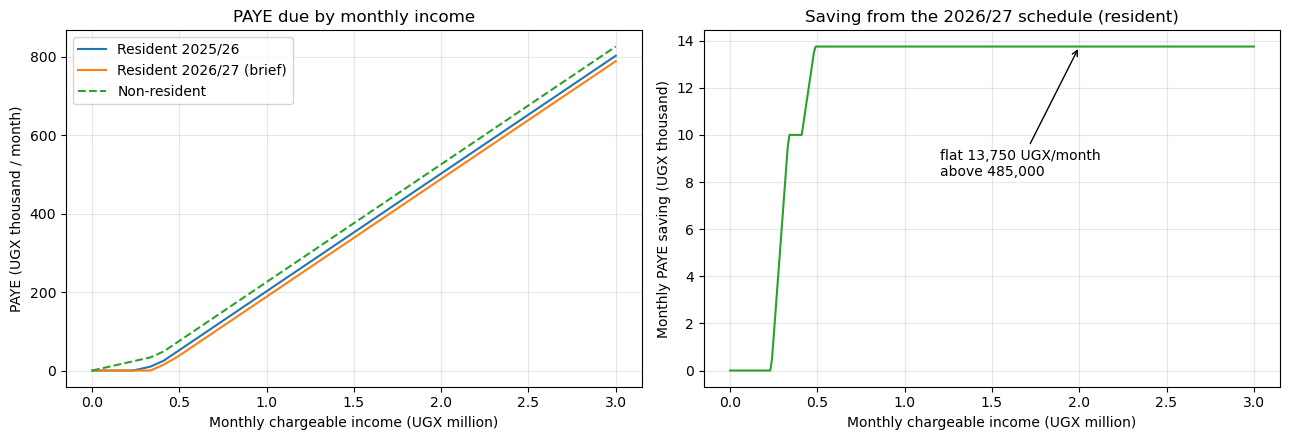

Largest saving: UGX 13,750/month; above 485,000 every resident saves UGX 13,750/month.


In [5]:
incomes = np.arange(0, 3_000_001, 10_000)
def series(on, resident):
    return np.array([int(paye.calculate(EmploymentContext(on=on, gross_pay=Money(int(x)), resident=resident)).amount.amount)
                     for x in incomes])
old, new, nonres = series(MAR_2026, True), series(OCT_2026, True), series(OCT_2026, False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
ax.plot(incomes / 1e6, old / 1e3, label="Resident 2025/26")
ax.plot(incomes / 1e6, new / 1e3, label="Resident 2026/27 (brief)")
ax.plot(incomes / 1e6, nonres / 1e3, "--", label="Non-resident")
ax.set_xlabel("Monthly chargeable income (UGX million)"); ax.set_ylabel("PAYE (UGX thousand / month)")
ax.set_title("PAYE due by monthly income"); ax.legend(); ax.grid(alpha=.3)
ax = axes[1]
saving = old - new
ax.plot(incomes / 1e6, saving / 1e3, color="tab:green")
ax.set_xlabel("Monthly chargeable income (UGX million)"); ax.set_ylabel("Monthly PAYE saving (UGX thousand)")
ax.set_title("Saving from the 2026/27 schedule (resident)"); ax.grid(alpha=.3)
ax.annotate(f"flat {saving[-1]:,} UGX/month\nabove 485,000", xy=(2.0, saving[-1] / 1e3), xytext=(1.2, saving[-1] / 1e3 * 0.6),
            arrowprops=dict(arrowstyle="->"))
fig.tight_layout(); fig.savefig(FIGURES / "p2_paye_schedules.png", dpi=150, bbox_inches="tight"); plt.show()
print(f"Largest saving: UGX {saving.max():,}/month; above 485,000 every resident saves UGX {saving[-1]:,}/month.")

The amendment helps low earners most in relative terms: someone on UGX 335,000 no longer pays the 10,000 they paid before. In absolute terms, the saving is capped at a flat UGX 13,750 a month for everyone above 485,000, because above that point both schedules charge 30% at the margin. The new schedule is therefore a fixed reduction for higher earners, not a cut in the top rate.

### 4.3 Errors are explicit

In [6]:
cases = {
    "date before any schedule": lambda: paye.calculate(EmploymentContext(on=date(2010, 1, 31), gross_pay=Money(500_000))),
    "negative pay": lambda: EmploymentContext(on=OCT_2026, gross_pay=Money(-1)),
    "wrong context type": lambda: paye.calculate(VATContext(on=OCT_2026)),
    "float instead of Money": lambda: EmploymentContext(on=OCT_2026, gross_pay=Money(1_500_000.75)),
}
for name, fn in cases.items():
    try:
        fn()
        print(f"{name}: no error (unexpected)")
    except (TaxError, TypeError) as exc:
        print(f"{name:<24} -> {type(exc).__name__}: {exc}")

date before any schedule -> NoScheduleForDateError: No PAYE schedule is in force on 2010-01-31
negative pay             -> InvalidIncomeError: gross_pay must not be negative, got Money('-1')
wrong context type       -> UnsupportedContextError: PAYE needs a EmploymentContext, got VATContext
float instead of Money   -> TypeError: Use int, str or Decimal for money and rates, not float (1500000.75)


## 5. Payroll pipeline

**Order of deductions, and the justification:**

1. **Local Service Tax** comes first. It is set by income band, collected over July–October, and deductible in computing chargeable income, so PAYE cannot be known until it is.
2. **PAYE** is charged on gross pay + taxable allowances − LST.
3. **NSSF 5%** is charged on gross wages. In Uganda the employee contribution is *not* deductible for PAYE, so it never feeds into step 2. The employer's 10% is an employer cost and never appears as a payslip deduction.
4. **Net pay** = gross + allowances − LST − PAYE − NSSF (employee).

`PayrollPipeline` *contains* the three taxes (composition) and returns a `Payslip`.

In [7]:
staff = [  # illustrative staff of a Kampala SME
    ("Cleaner",       Money(300_000),   Money(0)),
    ("Driver",        Money(450_000),   Money(50_000)),
    ("Accountant",    Money(1_800_000), Money(200_000)),
    ("Engineer",      Money(4_500_000), Money(500_000)),
    ("Director",      Money(12_000_000), Money(1_500_000)),
]
pipeline = PayrollPipeline(lst=LocalServiceTax(enabled=True))
slips = [pipeline.run(EmploymentContext(on=OCT_2026, gross_pay=g, allowances=a), name) for name, g, a in staff]
print(slips[2], "\n")
payroll = pd.DataFrame([s.as_row() for s in slips]).set_index("Employee")
payroll.loc["TOTAL"] = payroll.sum()
payroll.style.format("{:,.0f}")

Payslip: Accountant
  Gross pay                  UGX 1,800,000
  Allowances                   UGX 200,000
  Local Service Tax            -UGX 25,000
  PAYE                        -UGX 480,750
  NSSF employee 5%            -UGX 100,000
  Net pay                    UGX 1,394,250
  (Employer NSSF 10%)          UGX 200,000 



,Gross,Allowances,LST,PAYE,NSSF (5%),Net pay,Employer NSSF (10%),Employer cost
Employee,,,,,,,,
Cleaner,"300,000",0,"2,500",0,"15,000","282,500","30,000","330,000"
Driver,"450,000","50,000","7,500","36,000","25,000","431,500","50,000","550,000"
Accountant,"1,800,000","200,000","25,000","480,750","100,000","1,394,250","200,000","2,200,000"
Engineer,"4,500,000","500,000","25,000","1,380,750","250,000","3,344,250","500,000","5,500,000"
Director,"12,000,000","1,500,000","25,000","4,278,250","675,000","8,521,750","1,350,000","14,850,000"
TOTAL,"19,050,000","2,250,000","85,000","6,175,750","1,065,000","13,974,250","2,130,000","23,430,000"


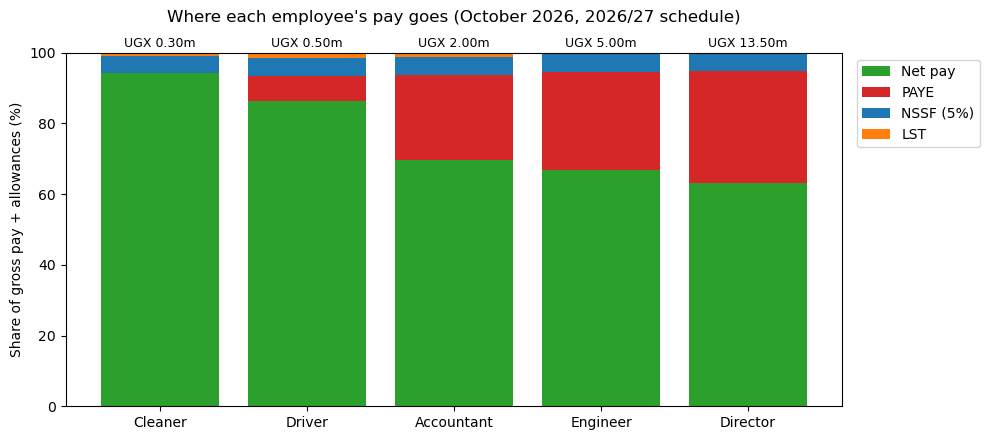

In [8]:
p = payroll.drop("TOTAL")
fig, ax = plt.subplots(figsize=(10, 4.5))
gross_total = (p["Gross"] + p["Allowances"]) / 1e6
bottom = np.zeros(len(p))
for col, colour in (("Net pay", "tab:green"), ("PAYE", "tab:red"), ("NSSF (5%)", "tab:blue"), ("LST", "tab:orange")):
    share = p[col] / (p["Gross"] + p["Allowances"]) * 100
    ax.bar(p.index, share, bottom=bottom, label=col, color=colour)
    bottom += share
ax.set_ylabel("Share of gross pay + allowances (%)")
ax.set_title("Where each employee's pay goes (October 2026, 2026/27 schedule)", pad=22)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1)); ax.set_ylim(0, 100)
for i, g in enumerate(gross_total):
    ax.text(i, 101.5, f"UGX {g:.2f}m", ha="center", fontsize=9)
fig.tight_layout(); fig.savefig(FIGURES / "p2_payroll.png", dpi=150, bbox_inches="tight"); plt.show()

In [9]:
print((p["Net pay"] / (p["Gross"] + p["Allowances"])).map("{:.1%}".format).rename("Share of pay kept").to_string())

Employee
Cleaner       94.2%
Driver        86.3%
Accountant    69.7%
Engineer      66.9%
Director      63.1%


PAYE is progressive. The cleaner keeps 94% of pay: no PAYE is due under the 2026/27 nil band, only NSSF and a small LST instalment. The director keeps 63%, because of the 30% marginal rate and the 10% surcharge above UGX 10 million. LST is small for everyone (at most UGX 25,000 a month) and is collected only from July to October.

## 6. VAT

Three supply types are handled:

* **standard-rated** supplies carry 18% output VAT;
* **zero-rated** supplies (for example exports) carry 0% but count as taxable, so input VAT on them stays creditable;
* **exempt** supplies are outside VAT, so input VAT is apportioned and partly lost.

Example: a Jinja food processor for one month.

In [10]:
vat = VAT()
invoices = (
    Invoice("S-001", Money(42_000_000), SupplyType.STANDARD),         # processed foods sold locally
    Invoice("S-002", Money(30_000_000), SupplyType.ZERO),             # exports to South Sudan
    Invoice("S-003", Money(8_000_000), SupplyType.EXEMPT),            # unprocessed maize sold as is
    Invoice("P-101", Money(25_000_000), SupplyType.STANDARD, is_sale=False),  # packaging, fuel, machinery service
    Invoice("P-102", Money(18_000_000), SupplyType.EXEMPT, is_sale=False),    # maize bought from farmers (no VAT)
)
result = vat.calculate(VATContext(on=OCT_2026, invoices=invoices))
print(result.explain())

VAT: base UGX 42,000,000, due UGX 3,510,000
  output VAT 18% on standard-rated sales of UGX 42,000,000    UGX 7,560,000
  zero-rated sales UGX 30,000,000 at 0%                              UGX 0
  exempt sales UGX 8,000,000 (no VAT)                                UGX 0
  input VAT on standard-rated purchases                      UGX 4,500,000
  creditable input VAT (90.0% taxable share)                 UGX 4,050,000
  net VAT payable (negative = credit)                        UGX 3,510,000
  note: Input VAT apportioned because the period includes exempt supplies.


Hand check:

* Output VAT = 18% × 42,000,000 = 7,560,000.
* Input VAT = 18% × 25,000,000 = 4,500,000.
* Taxable share = (42m + 30m) / 80m = 90%, so creditable input = 4,050,000.
* Net payable = **3,510,000**.

Two contrasting cases, an exporter and a purely exempt business:

In [11]:
exporter = VATContext(on=OCT_2026, invoices=(Invoice("E1", Money(50_000_000), SupplyType.ZERO),
                                             Invoice("P1", Money(20_000_000), SupplyType.STANDARD, False)))
clinic = VATContext(on=OCT_2026, invoices=(Invoice("S1", Money(15_000_000), SupplyType.EXEMPT),
                                           Invoice("P1", Money(5_000_000), SupplyType.STANDARD, False)))
for label, ctx in (("Coffee exporter (all zero-rated)", exporter), ("Clinic (all exempt)", clinic)):
    r = vat.calculate(ctx)
    print(f"{label:<34} net VAT {r.amount}   {' '.join(r.notes)}")

Coffee exporter (all zero-rated)   net VAT -UGX 3,600,000   Credit position: carry forward or claim a refund.
Clinic (all exempt)                net VAT UGX 0   Input VAT apportioned because the period includes exempt supplies.


The exporter is in a refund position of UGX 3.6 million, which is the purpose of zero-rating: exports leave Uganda free of VAT. The clinic pays no VAT but cannot reclaim the 900,000 of VAT on its purchases, so exemption is not the same as being VAT-free.

## 7. Corporate income tax

In [12]:
cit = CorporateIncomeTax()
company = CorporateContext(on=OCT_2026, revenue=Money(850_000_000), deductions={
    "cost of sales": Money(510_000_000), "salaries and NSSF": Money(140_000_000),
    "rent": Money(36_000_000), "depreciation (capital allowances)": Money(24_000_000)},
    losses_brought_forward=Money(15_000_000))
print(cit.calculate(company).explain())
loss_year = replace(company, revenue=Money(600_000_000))
print("\n" + cit.calculate(loss_year).explain())

Corporate income tax: base UGX 125,000,000, due UGX 37,500,000
  revenue                                                  UGX 850,000,000
  less cost of sales                                      -UGX 510,000,000
  less salaries and NSSF                                  -UGX 140,000,000
  less rent                                                -UGX 36,000,000
  less depreciation (capital allowances)                   -UGX 24,000,000
  less losses brought forward                              -UGX 15,000,000
  tax at 30% of chargeable income UGX 125,000,000           UGX 37,500,000

Corporate income tax: base UGX 0, due UGX 0
  revenue                                                  UGX 600,000,000
  less cost of sales                                      -UGX 510,000,000
  less salaries and NSSF                                  -UGX 140,000,000
  less rent                                                -UGX 36,000,000
  less depreciation (capital allowances)                   -UGX 24,

## 8. Polymorphism: one interface, many taxes

Every tax is used through the same `calculate` call. The context type tells each tax what it needs, and passing the wrong one is an error, not a silent zero.

In [13]:
emp = EmploymentContext(on=OCT_2026, gross_pay=Money(2_000_000))
jobs: list[tuple[Tax, object]] = [(PAYE(), emp), (NSSF(), emp), (LocalServiceTax(), emp),
                                  (VAT(), VATContext(on=OCT_2026, invoices=invoices)), (CorporateIncomeTax(), company)]
for tax, ctx in jobs:
    r = tax.calculate(ctx)
    print(f"{r.tax:<22} base {str(r.base):>18}  due {str(r.amount):>16}")

PAYE                   base      UGX 2,000,000  due      UGX 488,250
NSSF                   base      UGX 2,000,000  due      UGX 100,000
Local Service Tax      base      UGX 2,000,000  due       UGX 25,000
VAT                    base     UGX 42,000,000  due    UGX 3,510,000
Corporate income tax   base    UGX 125,000,000  due   UGX 37,500,000


## 9. Extensions (both attempted)

### 9A. Withholding tax and rental income tax

In [14]:
wht = WithholdingTax()
payments = [
    ("Supplier invoice, UGX 950,000 (below threshold)", WithholdingContext(on=OCT_2026, payment=Money(950_000))),
    ("Supplier invoice, UGX 4,000,000", WithholdingContext(on=OCT_2026, payment=Money(4_000_000))),
    ("Consultant's fees, resident", WithholdingContext(on=OCT_2026, payment=Money(6_000_000), payment_type=PaymentType.PROFESSIONAL_FEES)),
    ("Consultant's fees, non-resident", WithholdingContext(on=OCT_2026, payment=Money(6_000_000), payment_type=PaymentType.PROFESSIONAL_FEES, payee_resident=False)),
    ("Dividend to resident individual", WithholdingContext(on=OCT_2026, payment=Money(20_000_000), payment_type=PaymentType.DIVIDEND)),
    ("Dividend from listed company", WithholdingContext(on=OCT_2026, payment=Money(20_000_000), payment_type=PaymentType.DIVIDEND_LISTED)),
]
for label, ctx in payments:
    r = wht.calculate(ctx)
    print(f"{label:<50} WHT {str(r.amount):>14}  {' '.join(r.notes)}")

rental = RentalIncomeTax()
for rent in (2_400_000, 2_820_000, 18_000_000, 60_000_000):
    r = rental.calculate(RentalContext(on=OCT_2026, gross_rent=Money(rent)))
    print(f"Landlord with annual rent UGX {rent:>11,}: tax {r.amount}  (effective {r.effective_rate:.1%} of taxable excess)")

Supplier invoice, UGX 950,000 (below threshold)    WHT          UGX 0  below the UGX 1,000,000 threshold: no WHT
Supplier invoice, UGX 4,000,000                    WHT    UGX 240,000  
Consultant's fees, resident                        WHT    UGX 360,000  
Consultant's fees, non-resident                    WHT    UGX 900,000  
Dividend to resident individual                    WHT  UGX 3,000,000  
Dividend from listed company                       WHT  UGX 2,000,000  
Landlord with annual rent UGX   2,400,000: tax UGX 0  (effective 0.0% of taxable excess)
Landlord with annual rent UGX   2,820,000: tax UGX 0  (effective 0.0% of taxable excess)
Landlord with annual rent UGX  18,000,000: tax UGX 1,821,600  (effective 12.0% of taxable excess)
Landlord with annual rent UGX  60,000,000: tax UGX 6,861,600  (effective 12.0% of taxable excess)


### 9B. `TaxPlanner`: salary or dividend?

An owner-manager can take the company's monthly pre-tax profit as **salary**, which is deductible for the company but bears PAYE and NSSF, or as a **dividend**, which bears 30% corporate tax and then 15% WHT. `Scenario` is an abstract strategy, and `TaxPlanner` composes two of them. The assumptions are listed in `src/tax/planner.py`; the main ones are pro-rata monthly corporate tax, NSSF treated as a cost, and LST ignored.

In [15]:
planner = TaxPlanner(SalaryScenario(), DividendScenario())
for profit in (1_000_000, 5_000_000, 20_000_000):
    print(planner.compare(Money(profit), OCT_2026))
breakeven = planner.breakeven(OCT_2026)
print(f"\nBreak-even profit: about {breakeven} per month")

Salary: owner keeps UGX 702,659 (tax 29.7%); Dividend: owner keeps UGX 595,000 (tax 40.5%). Salary is better by UGX 107,659.
Salary: owner keeps UGX 3,066,295 (tax 38.7%); Dividend: owner keeps UGX 2,975,000 (tax 40.5%). Salary is better by UGX 91,295.
Salary: owner keeps UGX 11,111,750 (tax 44.4%); Dividend: owner keeps UGX 11,900,000 (tax 40.5%). Dividend is better by UGX 788,250.

Break-even profit: about UGX 11,703,377 per month


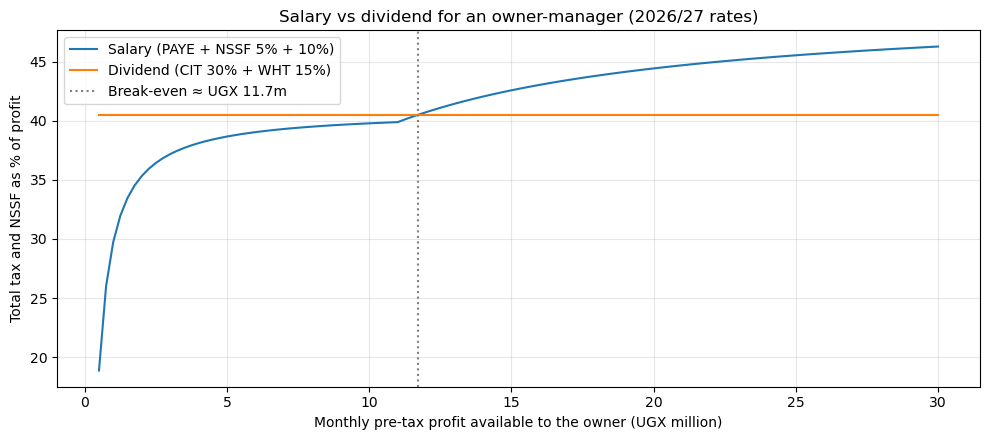

In [16]:
profits = np.arange(500_000, 30_000_001, 250_000)
comps = [planner.compare(Money(int(p)), OCT_2026) for p in profits]
fig, ax = plt.subplots(figsize=(10, 4.5))
# float() only here, at the plotting boundary: matplotlib draws floats; all tax arithmetic stayed in Decimal.
ax.plot(profits / 1e6, [float(c.a.effective_rate) * 100 for c in comps], label="Salary (PAYE + NSSF 5% + 10%)")
ax.plot(profits / 1e6, [float(c.b.effective_rate) * 100 for c in comps], label="Dividend (CIT 30% + WHT 15%)")
if breakeven:
    ax.axvline(float(breakeven.amount) / 1e6, color="grey", ls=":", label=f"Break-even ≈ UGX {float(breakeven.amount)/1e6:.1f}m")
ax.set_xlabel("Monthly pre-tax profit available to the owner (UGX million)")
ax.set_ylabel("Total tax and NSSF as % of profit")
ax.set_title("Salary vs dividend for an owner-manager (2026/27 rates)")
ax.legend(); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(FIGURES / "p2_salary_vs_dividend.png", dpi=150, bbox_inches="tight"); plt.show()

The dividend route costs a flat 40.5% (1 − 0.70 × 0.85). The salary route is cheap at low profits, because of the nil band, and rises towards 45.5% (30% PAYE + 10% surcharge, plus NSSF on a salary of P/1.1). Salary is better below roughly UGX 11.7 million a month, and dividends above it. The comparison treats NSSF as a pure cost. Counting NSSF as the owner's own savings, which it partly is, would move the break-even higher.

## 10. Tests

* **Boundary tests** cover every band edge in the brief (335,000; 335,001; 410,000; 485,000; 10,000,000; 10,000,001), with exact and rounded values. They also cover the 2025/26 and non-resident edges.
* **Property-based tests** with `hypothesis` check, for random incomes, dates and residency, that PAYE is **non-negative**, **monotonic in income** and **never exceeds income**. They also check that `Money` addition is exact and that rounding error stays within half a shilling.
* **Module tests** cover NSSF, the LST bands and months, a hand-computed payslip, VAT apportionment and refunds, corporate losses carried forward, WHT thresholds, rental tax and the planner's accounting identity.

In [17]:
result = subprocess.run([sys.executable, "-m", "pytest", "tests/test_tax.py", "tests/test_money.py", "--color=no",
                         "-p", "no:cacheprovider"], capture_output=True, text=True)
print(result.stdout[-400:] or result.stderr[-800:])

..........................................................               [100%]
58 passed in 0.63s



## 11. Discussion

### Q1. Why is `float` unsafe for tax computation? A concrete failing example

A `float` stores numbers in binary, and most decimal fractions (0.1, 0.18, 1500.10) have no exact binary form. Each value is silently replaced by the nearest binary fraction. Single multiplications often round back to the right answer, which is what makes the problem dangerous: the code passes simple checks and then fails on sums, conversions and comparisons, which is exactly what an invoice, a payroll run or a VAT return does.

In [18]:
lines = [1500.10, 1500.10, 1500.10]                  # three invoice lines in UGX (e.g. per-unit prices with cents)
total_f = sum(lines)
print("float sum of three 1,500.10 lines:", repr(total_f))
print("converted to cents with int():    ", int(total_f * 100), "   <- one cent lost (should be 450030)")
print("total == 4500.30 ?                ", total_f == 4500.30)
total_d = sum([Money("1500.10")] * 3)
print("Money sum:                         ", repr(total_d), "== Money('4500.30')?", total_d == Money("4500.30"))

# VAT reconciliation: VAT per line summed must equal VAT on the total. A URA audit check does exactly this.
amounts = [1_234.10, 19_999.90, 3.30, 77_777.70] * 25
print("\nfloat: VAT on lines summed == VAT on total?  ", sum(a * 0.18 for a in amounts) == sum(amounts) * 0.18,
      f"({sum(a * 0.18 for a in amounts)!r} vs {sum(amounts) * 0.18!r})")
m = [Money(Decimal(str(a))) for a in amounts]
print("Money: VAT on lines summed == VAT on total?  ", sum(x * Decimal('0.18') for x in m) == sum(m, Money.zero()) * Decimal('0.18'))

print("\nPython's round() is banker's rounding: round(0.5) =", round(0.5), ", round(2.5) =", round(2.5),
      " | Money half-up:", Money('0.5').round(), Money('2.5').round())

float sum of three 1,500.10 lines: 4500.299999999999
converted to cents with int():     450029    <- one cent lost (should be 450030)
total == 4500.30 ?                 False
Money sum:                          Money('4500.30') == Money('4500.30')? True

float: VAT on lines summed == VAT on total?   False (445567.49999999965 vs 445567.5)
Money: VAT on lines summed == VAT on total?   True

Python's round() is banker's rounding: round(0.5) = 0 , round(2.5) = 2  | Money half-up: UGX 1 UGX 3


Three separate failures appear above:

1. **Representation.** 1,500.10 × 3 is not 4,500.30 in float, so an equality check fails, and a cents conversion with `int()` loses a shilling-cent.
2. **Non-associativity.** VAT per line, summed, differs from VAT on the total. A reconciliation that should balance exactly does not, and someone wastes time chasing a phantom difference.
3. **Rounding mode.** `round()` rounds half to even, so a computed 2.5 shillings becomes 2, not the 3 a tax table expects.

`Decimal` represents decimal amounts exactly, makes the rounding mode explicit (`ROUND_HALF_UP`), and `Money` refuses floats at the door, so none of these can creep in. With large aggregates (a national payroll, a year of VAT returns), float errors also accumulate rather than cancel.

### Q2. Where inheritance is justified, and where I deliberately avoided it

**Used, where there is a true *is-a* relationship and a shared contract:**

* `Tax` → `PAYE`, `NSSF`, `LocalServiceTax`, `VAT`, `CorporateIncomeTax`, `WithholdingTax`, `RentalIncomeTax`. Every tax *is a* tax and must honour `calculate(ctx) -> TaxResult`. Callers (section 8, the planner) rely on that contract and nothing else.
* `TaxContext` → `EmploymentContext`, `VATContext`, and so on. Every context *is a* dated tax situation. The shared `on` date drives schedule selection everywhere.
* `Scenario` → `SalaryScenario`, `DividendScenario`. These are strategies with one abstract method.
* The exception hierarchy, so callers can catch `TaxError` broadly or `NoScheduleForDateError` narrowly. It also uses multiple inheritance from `ValueError` and `LookupError`, so generic handlers still work.

**Avoided on purpose:**

* **Resident vs non-resident PAYE are not subclasses.** They differ only in *data* (the bands), not in behaviour. Subclasses would duplicate logic and multiply with every Finance Act (`ResidentPAYE2026`, …). One `PAYE` class plus a date-keyed `ScheduleRegistry` handles every year and both residency statuses.
* **`PayrollPipeline` is not a `Tax`.** A payslip is not a tax; it *uses* three taxes. Composition lets the LST component be swapped or disabled without a subclass.
* **`Money` does not subclass `Decimal`.** If it did, it would inherit `Money * Money` and mixing with plain Decimals, exactly the operations that must be forbidden. Wrapping (composition) exposes only the meaningful operations.
* **`TaxPlanner` *has* scenarios rather than *being* one**, so any two strategies can be compared, including future ones such as a pension contribution.
* **VAT supply types are an `Enum`, not invoice subclasses.** Zero-rated and exempt invoices behave identically as records; only the VAT computation treats them differently.

The rule I followed: inherit to share an **interface** that clients depend on; compose, or use data, to vary **values**.

## 12. Summary

* The engine reproduces the brief's 2026/27 schedule exactly at every band edge. It also handles the 2025/26 schedule it replaced, chosen by date, and raises `NoScheduleForDateError` for dates before July 2012.
* All money is `Decimal`, rounded once, half-up, to the shilling. All 58 tax and money tests pass, including the hypothesis properties.
* The 2026 amendment saves residents a flat UGX 13,750 a month above UGX 485,000. For an owner-manager, salary beats dividends below about UGX 11.7 million of monthly profit.
* **Limitations.** Monthly PAYE only: there are no annual reconciliations, no tax on benefits-in-kind and no exempt allowances. The 2026/27 non-resident schedule is assumed unchanged. The LST bands should be confirmed with the local government. Corporate tax ignores capital allowances' detailed rules, small-business presumptive tax and provisional tax. The planner simplifies corporate tax to a monthly pro rata.